In [432]:
import torch
import torch.nn as nn
import math

# Input Embeddings

In [433]:
class InputEmbeddings(nn.Module):

    def __init__(self, d_model: int, vocab_size: int):
        super().__init__()
        self.d_model = d_model
        self.vocab_size = vocab_size
        self.embedding = nn.Embedding(vocab_size, d_model)

    def forward(self, x):
        return self.embedding(x) * math.sqrt(self.d_model)

# Positional Encodings

In [434]:
class PositionalEncoding(nn.Module):

    def __init__(self, max_seq_len: int, d_model: int):
        super().__init__()
        self.pos_embedding = nn.Embedding(max_seq_len, d_model)

    def forward(self, x):
        
        batch_size, seq_len = x.size()
        positions = torch.arange(seq_len, device=x.device).unsqueeze(0).expand(batch_size, seq_len)

        return self.pos_embedding(positions)


# Layer Normalization

Why LayerNorm MUST have α and β

Without them:

- All normalized vectors would look similar
- Model would lose expressive power
- Deep networks would be harder to train

α and β let the model undo some of the normalization when needed.

In [435]:
class LayerNormalization(nn.Module):

    def __init__(self, features: int, eps:float=10**-6):
        super().__init__()
        self.eps = eps
        self.alpha = nn.Parameter(torch.ones(features)) 
        self.bias = nn.Parameter(torch.zeros(features)) 

    def forward(self, x):
        mean = x.mean(dim = -1, keepdim = True) 
        std = x.std(dim = -1, keepdim = True) 
        return self.alpha * (x - mean) / (std + self.eps) + self.bias

# Feed Forward

In [436]:
class FeedForwardBlock(nn.Module):

    def __init__(self, d_model: int, d_ff: int, dropout: float):
        super().__init__()
        self.linear_1 = nn.Linear(d_model, d_ff) 
        self.dropout = nn.Dropout(dropout)
        self.linear_2 = nn.Linear(d_ff, d_model) 

    def forward(self, x):
        # (batch, seq_len, d_model) --> (batch, seq_len, d_ff) --> (batch, seq_len, d_model)
        return self.dropout(self.linear_2(torch.relu(self.linear_1(x))))
    # supposedly, you have to swap dropout with linear_2

# Multi-Head Attention

- Q: What I want
- K: Who am I
- V: What I will give you if you attended on me

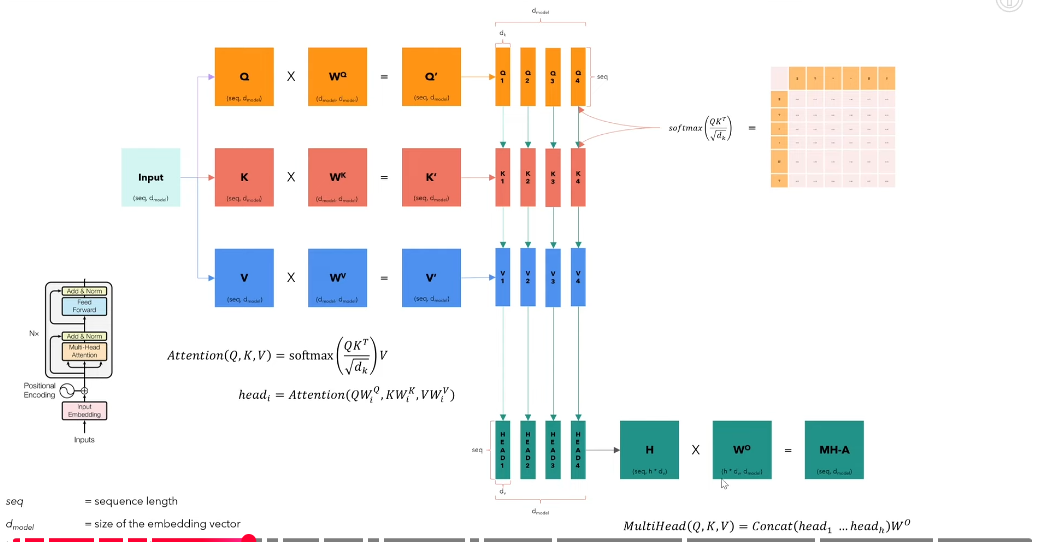

In [437]:
class MultiHeadAttentionBlock(nn.Module):

    def __init__(self, d_model: int, h: int, dropout: float):
        super().__init__()
        self.d_model = d_model 
        self.h = h 
        assert d_model % h == 0, "d_model is not divisible by h"
        self.dropout = nn.Dropout(dropout) # No dropout in the embedding layer and the attention weights

        self.d_k = d_model // h 
        self.w_q = nn.Linear(d_model, d_model, bias=False)
        self.w_k = nn.Linear(d_model, d_model, bias=False)
        self.w_v = nn.Linear(d_model, d_model, bias=False)
        self.w_o = nn.Linear(d_model, d_model, bias=False)

    @staticmethod
    def attention(query, key, value, mask, dropout: nn.Dropout):
        d_k = query.shape[-1]
        # (batch, h, seq_len, d_k) @ (batch, h, d_k, seq_len) --> (batch, h, seq_len, seq_len)
        attention_scores = (query @ key.transpose(-2, -1)) / math.sqrt(d_k)
        if mask is not None:
            attention_scores.masked_fill_(mask == 0, -1e9)
        attention_scores = attention_scores.softmax(dim=-1) # (batch, h, seq_len, seq_len) 
        if dropout is not None:
            attention_scores = dropout(attention_scores)
        # (batch, h, seq_len, seq_len) @ (batch, h, seq_len, d_k) --> (batch, h, seq_len, d_k)
        # return attention scores which can be used for visualization
        return (attention_scores @ value), attention_scores

    def forward(self, q, k, v, mask):
        query = self.w_q(q) # (batch, seq_len, d_model) --> (batch, seq_len, d_model)
        key = self.w_k(k)   # (batch, seq_len, d_model) --> (batch, seq_len, d_model)
        value = self.w_v(v) # (batch, seq_len, d_model) --> (batch, seq_len, d_model)

        # (batch, seq_len, d_model) --> (batch, seq_len, h, d_k) --> (batch, h, seq_len, d_k)
        query = query.view(query.shape[0], query.shape[1], self.h, self.d_k).transpose(1, 2)
        key = key.view(key.shape[0], key.shape[1], self.h, self.d_k).transpose(1, 2)
        value = value.view(value.shape[0], value.shape[1], self.h, self.d_k).transpose(1, 2)

        x, self.attention_scores = MultiHeadAttentionBlock.attention(query, key, value, mask, self.dropout)
        
        # Combine all the heads together
        # (batch, h, seq_len, d_k) --> (batch, seq_len, h, d_k) --> (batch, seq_len, d_model)
        x = x.transpose(1, 2).contiguous().view(x.shape[0], -1, self.h * self.d_k)

        # (batch, seq_len, d_model) --> (batch, seq_len, d_model)  
        return self.w_o(x)

# Residual Connection

In [438]:
class ResidualConnection(nn.Module):
    
    def __init__(self, features: int, dropout: float):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.norm = LayerNormalization(features)

    def forward(self, x, sublayer):
        return x + self.dropout(sublayer(self.norm(x)))

# Encoder

In [439]:
class EncoderBlock(nn.Module):

    def __init__(self, features: int, self_attention_block: MultiHeadAttentionBlock, feed_forward_block: FeedForwardBlock, dropout: float):
        super().__init__()
        self.self_attention_block = self_attention_block
        self.feed_forward_block = feed_forward_block
        self.residual_connections = nn.ModuleList([ResidualConnection(features, dropout) for _ in range(2)])

    def forward(self, x, src_mask):
        x = self.residual_connections[0](x, lambda x: self.self_attention_block(x, x, x, src_mask))
        x = self.residual_connections[1](x, self.feed_forward_block)
        return x
        
class Encoder(nn.Module):

    def __init__(self, features: int, layers: nn.ModuleList):
        super().__init__()
        self.layers = layers
        self.norm = LayerNormalization(features)

    def forward(self, x, mask):
        for layer in self.layers:
            x = layer(x, mask)
        return self.norm(x)

# Decoder

In [440]:
class DecoderBlock(nn.Module):

    def __init__(self, features: int, self_attention_block: MultiHeadAttentionBlock, cross_attention_block: MultiHeadAttentionBlock, feed_forward_block: FeedForwardBlock, dropout: float):
        super().__init__()
        self.self_attention_block = self_attention_block
        self.cross_attention_block = cross_attention_block
        self.feed_forward_block = feed_forward_block
        self.residual_connections = nn.ModuleList([ResidualConnection(features, dropout) for _ in range(3)])

    def forward(self, x, encoder_output, src_mask, tgt_mask):
        x = self.residual_connections[0](x, lambda x: self.self_attention_block(x, x, x, tgt_mask))
        x = self.residual_connections[1](x, lambda x: self.cross_attention_block(x, encoder_output, encoder_output, src_mask))
        x = self.residual_connections[2](x, self.feed_forward_block)
        return x
    
class Decoder(nn.Module):

    def __init__(self, features: int, layers: nn.ModuleList):
        super().__init__()
        self.layers = layers
        self.norm = LayerNormalization(features)

    def forward(self, x, encoder_output, src_mask, tgt_mask):
        for layer in self.layers:
            x = layer(x, encoder_output, src_mask, tgt_mask)
        return self.norm(x)

# Linear Layer

In [441]:
class ProjectionLayer(nn.Module):

    def __init__(self, d_model, vocab_size):
        super().__init__()
        self.proj = nn.Linear(d_model, vocab_size)

    def forward(self, x) -> None:
        # (batch, seq_len, d_model) --> (batch, seq_len, vocab_size)
        return self.proj(x)

# Transformer

In [442]:
class Transformer(nn.Module):

    def __init__(self, encoder: Encoder, decoder: Decoder, src_embed: InputEmbeddings, tgt_embed: InputEmbeddings, src_pos: PositionalEncoding, tgt_pos: PositionalEncoding, projection_layer: ProjectionLayer) -> None:
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.src_embed = src_embed
        self.tgt_embed = tgt_embed
        self.src_pos = src_pos
        self.tgt_pos = tgt_pos
        self.projection_layer = projection_layer

    def encode(self, src, src_mask):
        # src: (batch, seq_len)
        pos = self.src_pos(src)            # (batch, seq_len, d_model)
        src = self.src_embed(src) + pos    # (batch, seq_len, d_model)
        return self.encoder(src, src_mask)
    
    def decode(self, encoder_output, src_mask, tgt, tgt_mask):
        # tgt: (batch, seq_len)
        pos = self.tgt_pos(tgt)            # (batch, seq_len, d_model)
        tgt = self.tgt_embed(tgt) + pos
        return self.decoder(tgt, encoder_output, src_mask, tgt_mask)

    
    def project(self, x):
        # (batch, seq_len, vocab_size)
        return self.projection_layer(x)

# Final integration stage

### Load parallel data

In [443]:
def load_parallel_data(path):
    with open(path, encoding="utf-8") as f:
        lines = f.readlines()
    src_sentences = []
    tgt_sentences = []
    for line in lines:
        src, tgt = line.strip().split("\t")
        src_sentences.append(src)
        tgt_sentences.append(tgt)
    return src_sentences, tgt_sentences

### Tokenize sentence pair

In [444]:
def tokenize_pair(fr_text, en_text, tokenizer_fr, tokenizer_en, max_len, TOKENS):
    fr_ids = tokenizer_fr.encode(fr_text).ids
    en_ids = tokenizer_en.encode(en_text).ids

    fr_ids = fr_ids[:max_len-2]
    en_ids = en_ids[:max_len-2]

    fr_ids = [TOKENS["BOS_FR"]] + fr_ids + [TOKENS["EOS_FR"]]
    en_ids = [TOKENS["BOS_EN"]] + en_ids + [TOKENS["EOS_EN"]]

    fr_ids += [TOKENS["PAD_FR"]] * (max_len - len(fr_ids))
    en_ids += [TOKENS["PAD_EN"]] * (max_len - len(en_ids))

    return fr_ids, en_ids


### Masks

##### Source Mask

In [445]:
def create_src_mask(src, pad_id):
    return (src != pad_id).unsqueeze(1).unsqueeze(2)

#### Target Mask

In [446]:
def create_tgt_mask(tgt, pad_id):
    seq_len = tgt.size(1)
    pad_mask = (tgt != pad_id).unsqueeze(1).unsqueeze(2)
    causal_mask = torch.tril(torch.ones(seq_len, seq_len)).bool()
    return pad_mask & causal_mask

### Building the Transformer

In [447]:
def build_transformer(src_vocab_size: int, tgt_vocab_size: int, src_seq_len: int, tgt_seq_len: int, dropout: float=0.1, d_model: int=32, N: int=3, h: int=4, d_ff: int=128):
    src_embed = InputEmbeddings(d_model, src_vocab_size)
    tgt_embed = InputEmbeddings(d_model, tgt_vocab_size)

    src_pos = PositionalEncoding(src_seq_len, d_model)
    tgt_pos = PositionalEncoding(tgt_seq_len, d_model)
    
    encoder_blocks = []
    for _ in range(N):
        encoder_self_attention_block = MultiHeadAttentionBlock(d_model, h, dropout)
        feed_forward_block = FeedForwardBlock(d_model, d_ff, dropout)
        encoder_block = EncoderBlock(d_model, encoder_self_attention_block, feed_forward_block, dropout)
        encoder_blocks.append(encoder_block)

    decoder_blocks = []
    for _ in range(N):
        decoder_self_attention_block = MultiHeadAttentionBlock(d_model, h, dropout)
        decoder_cross_attention_block = MultiHeadAttentionBlock(d_model, h, dropout)
        feed_forward_block = FeedForwardBlock(d_model, d_ff, dropout)
        decoder_block = DecoderBlock(d_model, decoder_self_attention_block, decoder_cross_attention_block, feed_forward_block, dropout)
        decoder_blocks.append(decoder_block)
    
    encoder = Encoder(d_model, nn.ModuleList(encoder_blocks))
    decoder = Decoder(d_model, nn.ModuleList(decoder_blocks))
    
    projection_layer = ProjectionLayer(d_model, tgt_vocab_size)
    
    transformer = Transformer(encoder, decoder, src_embed, tgt_embed, src_pos, tgt_pos, projection_layer)
    
    for p in transformer.parameters():
        if p.dim() > 1:
            nn.init.xavier_uniform_(p)
    
    return transformer

### Training Loop

#### Train one epoch

In [ ]:
import torch
import torch.nn as nn

def train_one_epoch(model, dataset, tokenizer_fr, tokenizer_en, TOKENS, optimizer, criterion):
    model.train()
    total_loss = 0

    for sample in dataset:
        fr_text = sample["text_fr"]
        en_text = sample["text_en"]

        src_ids, tgt_ids = tokenize_pair(
            fr_text, en_text,
            tokenizer_fr, tokenizer_en,
            max_len=32,
            TOKENS=TOKENS
        )

        src = torch.tensor(src_ids).unsqueeze(0)
        tgt = torch.tensor(tgt_ids).unsqueeze(0)

        src_mask = create_src_mask(src, TOKENS["PAD_FR"])
        tgt_input  = tgt[:, :-1]
        tgt_output = tgt[:, 1:]
        tgt_mask = create_tgt_mask(tgt_input, TOKENS["PAD_EN"])

        encoder_out = model.encode(src, src_mask)
        decoder_out = model.decode(encoder_out, src_mask, tgt_input, tgt_mask)
        logits = model.project(decoder_out)

        loss = criterion(
            logits.view(-1, logits.size(-1)),
            tgt_output.view(-1)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataset)

#### Training Process ( 10 Epochs )

#### Dataset Loading

In [449]:
from datasets import load_from_disk

def load_datasets(dataset_path):
    train_ds = load_from_disk(f"{dataset_path}/train")
    val_ds   = load_from_disk(f"{dataset_path}/validation")
    test_ds  = load_from_disk(f"{dataset_path}/test")

    return train_ds, val_ds, test_ds

#### Tokenizers Loading

In [450]:
from tokenizers import Tokenizer

def load_tokenizers(tokenizer_fr_path, tokenizer_en_path):
    tokenizer_fr = Tokenizer.from_file(tokenizer_fr_path)
    tokenizer_en = Tokenizer.from_file(tokenizer_en_path)

    special_tokens = {
        "PAD_FR": tokenizer_fr.token_to_id("<pad>"),
        "BOS_FR": tokenizer_fr.token_to_id("<s>"),
        "EOS_FR": tokenizer_fr.token_to_id("</s>"),
        "PAD_EN": tokenizer_en.token_to_id("<pad>"),
        "BOS_EN": tokenizer_en.token_to_id("<s>"),
        "EOS_EN": tokenizer_en.token_to_id("</s>")
    }

    return tokenizer_fr, tokenizer_en, special_tokens

### Loading dataset and tokenizers

In [451]:
# Loading dataset
train_data, val_data, test_data = load_datasets(
    "resources-20251214T045019Z-3-001/resources/parallel_en_fr_corpus"
)

# Loading Tokenizers
tokenizer_fr, tokenizer_en, TOKENS = load_tokenizers(
    "resources-20251214T045019Z-3-001/resources/tokenizer_fr/tokenizer.json",
    "resources-20251214T045019Z-3-001/resources/tokenizer_en/tokenizer.json"
)

### Minimal loaders print-test

In [452]:
# ---- Sanity checks ----

print("Train / Val / Test sizes:")
print(len(train_data), len(val_data), len(test_data))

print(train_data.column_names)
sample = train_data[0]
print("SRC:", sample["text_en"])
print("TGT:", sample["text_fr"])

print("\nTokenizer test:")
enc = tokenizer_fr.encode("je suis dure")
print("Token IDs:", enc.ids)
print("Tokens:", enc.tokens)

print("\nSpecial tokens:")
for tok in ["<pad>", "<s>", "</s>"]:
    print(tok, "->", tokenizer_en.token_to_id(tok))

Train / Val / Test sizes:
8701 485 486
['text_en', 'text_fr']
SRC: i m tough .
TGT: je suis dure .

Tokenizer test:
Token IDs: [1, 47, 60, 1449, 2]
Tokens: ['<s>', '▁je', '▁suis', '▁dure', '</s>']

Special tokens:
<pad> -> 3
<s> -> 1
</s> -> 2


In [453]:
import os

# Build transformer model
model = build_transformer(
    src_vocab_size=8000,
    tgt_vocab_size=8000,
    src_seq_len=32,
    tgt_seq_len=32,
    dropout=0.1,
    d_model=32,
    N=3,
    h=4,
    d_ff=128
)

# Loss & Optimizer
criterion = nn.CrossEntropyLoss(ignore_index=TOKENS["PAD_EN"])
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

if os.path.exists("transformer_en_fr.pth"):
    model.load_state_dict(torch.load("transformer_en_fr.pth"))
else:
    for epoch in range(10):
        loss = train_one_epoch(model, train_data, tokenizer_fr, tokenizer_en, TOKENS, optimizer, criterion)
        print(f"Epoch {epoch+1}, Loss: {loss:.4f}")
    torch.save(model.state_dict(), "transformer_en_fr.pth")

Epoch 1, Loss: 2.2760
Epoch 2, Loss: 1.6559
Epoch 3, Loss: 1.4420
Epoch 4, Loss: 1.2870
Epoch 5, Loss: 1.1656
Epoch 6, Loss: 1.0675
Epoch 7, Loss: 0.9852
Epoch 8, Loss: 0.9138
Epoch 9, Loss: 0.8575
Epoch 10, Loss: 0.8038


## Inference ( actual translation )

#### Translate sentence

In [454]:
def translate(model, sentence, tokenizer_fr, tokenizer_en, TOKENS, max_len=32):
    model.eval()

    src_ids = tokenizer_fr.encode(sentence).ids
    src_ids = [TOKENS["BOS_FR"]] + src_ids + [TOKENS["EOS_FR"]]
    src_ids += [TOKENS["PAD_FR"]] * (max_len - len(src_ids))

    src = torch.tensor(src_ids).unsqueeze(0)
    src_mask = create_src_mask(src, TOKENS["PAD_FR"])

    encoder_out = model.encode(src, src_mask)

    tgt_ids = [TOKENS["BOS_EN"]]

    for _ in range(max_len):
        tgt = torch.tensor(tgt_ids).unsqueeze(0)
        tgt_mask = create_tgt_mask(tgt, TOKENS["PAD_EN"])

        decoder_out = model.decode(encoder_out, src_mask, tgt, tgt_mask)
        logits = model.project(decoder_out)

        next_token = logits.argmax(dim=-1)[0, -1].item()
        tgt_ids.append(next_token)

        if next_token == TOKENS["EOS_EN"]:
            break

    return tokenizer_en.decode(tgt_ids)

#### Final sanity-check example

In [455]:
sentence = "Je suis"
translation = translate(model, sentence, tokenizer_fr, tokenizer_en,TOKENS)
print(translation)

▁you ▁re ▁eating ▁.


# .................................................................................

# testing the code (remove it) just see how masking is implemented

In [456]:
# import torch

# # -----------------------------
# # CONFIG
# # -----------------------------
# src_vocab = 50
# tgt_vocab = 60
# src_seq_len = 10
# tgt_seq_len = 12
# batch_size = 2

# # -----------------------------
# # Create your transformer
# # -----------------------------
# model = build_transformer(
#     src_vocab_size=src_vocab,
#     tgt_vocab_size=tgt_vocab,
#     src_seq_len=src_seq_len,
#     tgt_seq_len=tgt_seq_len,
#     dropout=0.1,
#     d_model=32,
#     N=3,
#     h=4,
#     d_ff=128
# )

# # -----------------------------
# # Dummy input tensors
# # random token ids
# # -----------------------------
# src = torch.randint(0, src_vocab, (batch_size, src_seq_len))
# tgt = torch.randint(0, tgt_vocab, (batch_size, tgt_seq_len))

# # -----------------------------
# # Masks
# # -----------------------------
# # padding masks => all ones (no padding)
# src_mask = torch.ones(batch_size, 1, 1, src_seq_len)
# tgt_mask = torch.ones(batch_size, 1, tgt_seq_len, tgt_seq_len)

# # causal mask for decoder
# causal = torch.tril(torch.ones(tgt_seq_len, tgt_seq_len)).bool()
# tgt_mask = tgt_mask * causal

# # -----------------------------
# # Forward pass
# # -----------------------------
# enc_out = model.encode(src, src_mask)
# dec_out = model.decode(enc_out, src_mask, tgt, tgt_mask)
# logits = model.project(dec_out)

# print("src shape:", src.shape)
# print("encoder output:", enc_out.shape)
# print("decoder output:", dec_out.shape)
# print("logits shape:", logits.shape)     # should be (batch, tgt_seq_len, tgt_vocab)
